# Band noise NEL MODELLO di analisi: dati reali DR2low

Dati **reali** di J1640+2224 (DR2low) analizzati con il modello a **8 parametri**: i 6 standard (alpha = 4.4)
+ `band_noise_log10_A` e `band_noise_gamma` sui backend LOFAR, 50 componenti.

Domanda: i dati reali vogliono un band noise LOFAR?
- se `band_noise_log10_A` e vincolato (picco staccato dal bordo inferiore del prior) -> c e evidenza di band noise;
- se la posteriore e piatta verso -20 e cade sopra una soglia -> solo upper limit, come nella simulazione a -14.

Confronto con la run reale a 6 parametri con alpha = 4.4 del notebook 10 (`test_real_sv44/`).

Prior del band noise: log10_A ~ U(-20, -11), gamma ~ U(0, 7), come gli altri processi (Iraci et al. 2025, Tab. A.1).

## Setup comune

In [1]:
import numpy as np
import os, glob, json
import pickle

import sys

# this is the path to the discovery folder
sys.path.insert(0, "./")
import discovery_new as ds

import matplotlib.pyplot as plt
import scipy
import jax.numpy as jnp

from scipy.stats import uniform
import re
from PTMCMCSampler.PTMCMCSampler import PTSampler as ptmcmc
import jax

import time
import emcee
import corner

Optional mpi4py package is not installed.  MPI support is not available.


In [2]:
##### Cell for the prior distributions ###################################################################################

my_priordict = {}
my_priordict["(.*_)?sv_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?sv_gp_alpha.*"] = [0, 10]
my_priordict["(.*_)?sv_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_log10_A.*"] = [-10, 1]
my_priordict["(.*_)?sw_gamma.*"] = [-5, 6]
my_priordict["(.*_)?dm_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?dm_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?red_noise_gamma.*"] = [0, 7]
my_priordict["(.*_)?red_noise_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_n_earth.*"] = [0, 30]
# band noise: stesse prior degli altri processi power-law
my_priordict["(.*_)?band_noise_gamma.*"] = [0, 7]
my_priordict["(.*_)?band_noise_log10_A.*"] = [-20, -11]


def build_priors(param_names, priordict):
    """
    Build a {param_name: scipy dist} dict with uniform prior distributions in the range
    """
    priors = {}
    unmatched = []
    for name in param_names:
        matched = False
        for pattern, (lo, hi) in priordict.items():
            if re.fullmatch(pattern, name):
                priors[name] = uniform(loc=lo, scale=hi - lo)
                matched = True
                break
        if not matched:
            unmatched.append(name)

    if unmatched:
        print(f"Warning: no prior found for {len(unmatched)} parameters, "
              f"falling back to standard normal:\n  {unmatched}")
    return priors

## Modello di analisi

Stessa funzione del notebook 19. Con `band_noise=False` da il modello standard a 6 parametri,
che serve solo per l ordine delle colonne della catena del notebook 10.

In [3]:
def costruisci_modello(p, band_noise=True, components_bn=50):
    # data
    model = [p.residuals]
    # timing model
    model += [ds.makegp_timing(p, svd=True)]
    # white noise parameters
    model += [ds.makenoise_measurement(p, p.noisedict, tnequad=True, ecorr=True)]
    # red noise parameters
    model.append(ds.makegp_fourier(p, ds.powerlaw, p.noisedict[p.name + '_red_components'], T=ds.getspan(p), name='red_noise'))
    # DM variation parameters
    model.append(ds.makegp_fourier(p, ds.powerlaw, p.noisedict[p.name + '_dm_components'], T=ds.getspan(p), name='dm_gp',
                                   fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
    # scattering noise parameters (alpha = 4.4, come nella simulazione)
    model.append(ds.makegp_fourier(p, ds.powerlaw, p.noisedict[p.name + '_chrom_components'], T=ds.getspan(p), name='sv_gp',
                                   fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))
    # band noise sui backend LOFAR
    if band_noise:
        model.append(ds.makegp_fourier_select(p, ds.powerlaw, components=components_bn, T=ds.getspan(p),
                                              name='band_noise', selection=ds.lofar_backends))
    return model

## Dati reali

In [4]:
# path to the folder with the data
path = './dati/DR2low_feathers/'
s_dsfiles = np.sort(os.listdir(path))
psr = [ds.pulsar.Pulsar.read_feather(path + f'{psrfile}') for psrfile in s_dsfiles][9] # we are only analysing pulsar #9
print('pulsar :', psr.name)
print('N_TOA  :', len(psr.toas))

# selezione LOFAR: deve essere UNA sola (un solo processo di band noise per tutta la banda)
sel = ds.lofar_backends(psr)
print('selezioni LOFAR :', list(sel.keys()))

pulsar : J1640+2224
N_TOA  : 6777
selezioni LOFAR : ['DE601.150', 'DE602.150', 'DE603.150', 'DE604.150', 'DE605.150', 'DE609.150', 'LOFAR.150']


## Modello a 8 parametri

In [5]:
logL_real_bn = ds.PulsarLikelihood(costruisci_modello(psr)).logL
logL_real_bn.params

['J1640+2224_band_noise_gamma',
 'J1640+2224_band_noise_log10_A',
 'J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [6]:
def params_dict_from_array_real_bn(x):
    x = np.asarray(x)
    return dict(zip(logL_real_bn.params, x))

priors_real_bn = build_priors(logL_real_bn.params, my_priordict)   # nessun warning atteso

def log_prior_real_bn(x):
    params = params_dict_from_array_real_bn(x)
    logp = 0.0
    for name, value in params.items():
        logp += priors_real_bn[name].logpdf(value)
    return logp

def prior_draw_real_bn():
    return np.array([priors_real_bn[name].rvs() for name in logL_real_bn.params])

x0_real_bn = prior_draw_real_bn()
x0_real_bn

array([  5.01135756, -15.79637877,   0.18034585, -14.91549424,
         2.57341226, -19.53119325,   5.83014452, -12.63651131])

In [7]:
@jax.jit
def _jit_logL_real_bn(params_array):
    return logL_real_bn(dict(zip(logL_real_bn.params, params_array)))

def log_likelihood_real_bn(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_real_bn(jnp.array(x))))

print('logL iniziale =', log_likelihood_real_bn(x0_real_bn))

# tempo di una valutazione, per stimare la durata del sampling
start = time.time()
for _ in range(20):
    log_likelihood_real_bn(x0_real_bn)
dt = (time.time() - start) / 20
print(f'una valutazione = {dt*1e3:.1f} ms  ->  10^6 iterazioni ~ {dt*1e6/3600:.1f} ore')

logL iniziale = 67688.5156022893
una valutazione = 2.0 ms  ->  10^6 iterazioni ~ 0.6 ore


In [8]:
sampler_real_bn = ptmcmc(
    ndim=len(logL_real_bn.params),
    logl=log_likelihood_real_bn,
    logp=log_prior_real_bn,
    cov=np.eye(len(logL_real_bn.params)) * 0.001,
    outDir='./test_real_bn_bnmodel/',
    resume=True
)

### Sampling

Eseguire **una sola volta**; poi per rifare i grafici ripartire dalla cella che legge `chain_1.txt`.

In [10]:
ESEGUI_SAMPLING_REAL = True   # True solo per lanciare davvero il campionamento

if ESEGUI_SAMPLING_REAL:
    sampler_real_bn.sample(x0_real_bn, Niter=1000000, thin=10)

Finished 1.00 percent (1.00 percent of new work) in 18.753493 s Acceptance rate = 0.244Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 1829.702790 s Acceptance rate = 0.1432
Run Complete


## Catena e risultati

In [11]:
chain_real_bn = np.loadtxt('./test_real_bn_bnmodel/chain_1.txt')
chain_real_bn = chain_real_bn[len(chain_real_bn)//4:, :-4]   # 25% di burn-in, via le 4 colonne diagnostiche

tau = emcee.autocorr.integrated_time(chain_real_bn, has_walkers=False, quiet=True)
print('campioni         =', len(chain_real_bn))
print('tau              =', np.round(tau, 1))
print('Effective sample size =', int(len(chain_real_bn) / tau.max()))

idx_real_bn = {name: i for i, name in enumerate(logL_real_bn.params)}

campioni         = 75001
tau              = [ 77.5  96.  182.9 183.3  26.9  11.3 133.1 147.1]
Effective sample size = 409


In [12]:
# mediana e intervallo al 68% di ogni parametro
for name in logL_real_bn.params:
    q16, q50, q84 = np.percentile(chain_real_bn[:, idx_real_bn[name]], [16, 50, 84])
    print(f"{name.replace('J1640+2224_', ''):22s} {q50:8.3f}  [{q16:8.3f}, {q84:8.3f}]")

band_noise_gamma          3.394  [   1.306,    5.779]
band_noise_log10_A      -14.551  [ -18.086,  -12.692]
dm_gp_gamma               2.480  [   1.890,    6.115]
dm_gp_log10_A           -13.898  [ -15.519,  -13.768]
red_noise_gamma           0.263  [   0.072,    0.579]
red_noise_log10_A       -13.241  [ -13.340,  -13.150]
sv_gp_gamma               1.755  [   0.999,    3.939]
sv_gp_log10_A           -16.560  [ -17.968,  -16.272]


### Il band noise e rivelato?

Due numeri sulla posteriore di `band_noise_log10_A`:

- **95° percentile**: se il band noise non e rivelato, e l upper limit. Attenzione: con il prior log-uniforme dipende
  dal bordo inferiore (-20); un upper limit "pulito" va rifatto con prior uniforme in A.
- **Savage-Dickey**: il modello senza band noise equivale a log10_A al bordo inferiore del prior. Il rapporto fra
  densita a posteriori e densita a priori in quella zona stima il Bayes factor *senza / con* band noise:
  ~1 -> i dati non distinguono, << 1 -> i dati vogliono il band noise.

In [13]:
lA = chain_real_bn[:, idx_real_bn['J1640+2224_band_noise_log10_A']]

print(f'95 percentile di band_noise_log10_A = {np.percentile(lA, 95):.2f}')

# Savage-Dickey: densita nel primo intervallo [-20, -19] del prior
lo, hi = -20, -19
dens_post  = np.mean((lA >= lo) & (lA < hi)) / (hi - lo)
dens_prior = 1 / (-11 - (-20))
print(f'densita a posteriori in [{lo}, {hi}] = {dens_post:.3f}')
print(f'densita a priori                    = {dens_prior:.3f}')
print(f'Bayes factor senza/con band noise  ~ {dens_post / dens_prior:.2f}')

95 percentile di band_noise_log10_A = -12.21
densita a posteriori in [-20, -19] = 0.083
densita a priori                    = 0.111
Bayes factor senza/con band noise  ~ 0.74


In [14]:
# confronto fra le log-likelihood massime: modello a 6 par (notebook 10) vs modello a 8 par
def logl_col(path):
    c = np.loadtxt(path)
    c = c[len(c)//4:]
    return c[:, -3]   # colonna della log-likelihood

ll_6par = logl_col('./test_real_sv44/chain_1.txt')
ll_8par = logl_col('./test_real_bn_bnmodel/chain_1.txt')

print(f'6 par : logL max {ll_6par.max():.2f}, mediana {np.median(ll_6par):.2f}')
print(f'8 par : logL max {ll_8par.max():.2f}, mediana {np.median(ll_8par):.2f}')
print(f'Delta logL max (8 - 6) = {ll_8par.max() - ll_6par.max():+.2f}')

6 par : logL max 68237.74, mediana 68234.71
8 par : logL max 68239.80, mediana 68235.02
Delta logL max (8 - 6) = +2.06


### Corner a 8 parametri

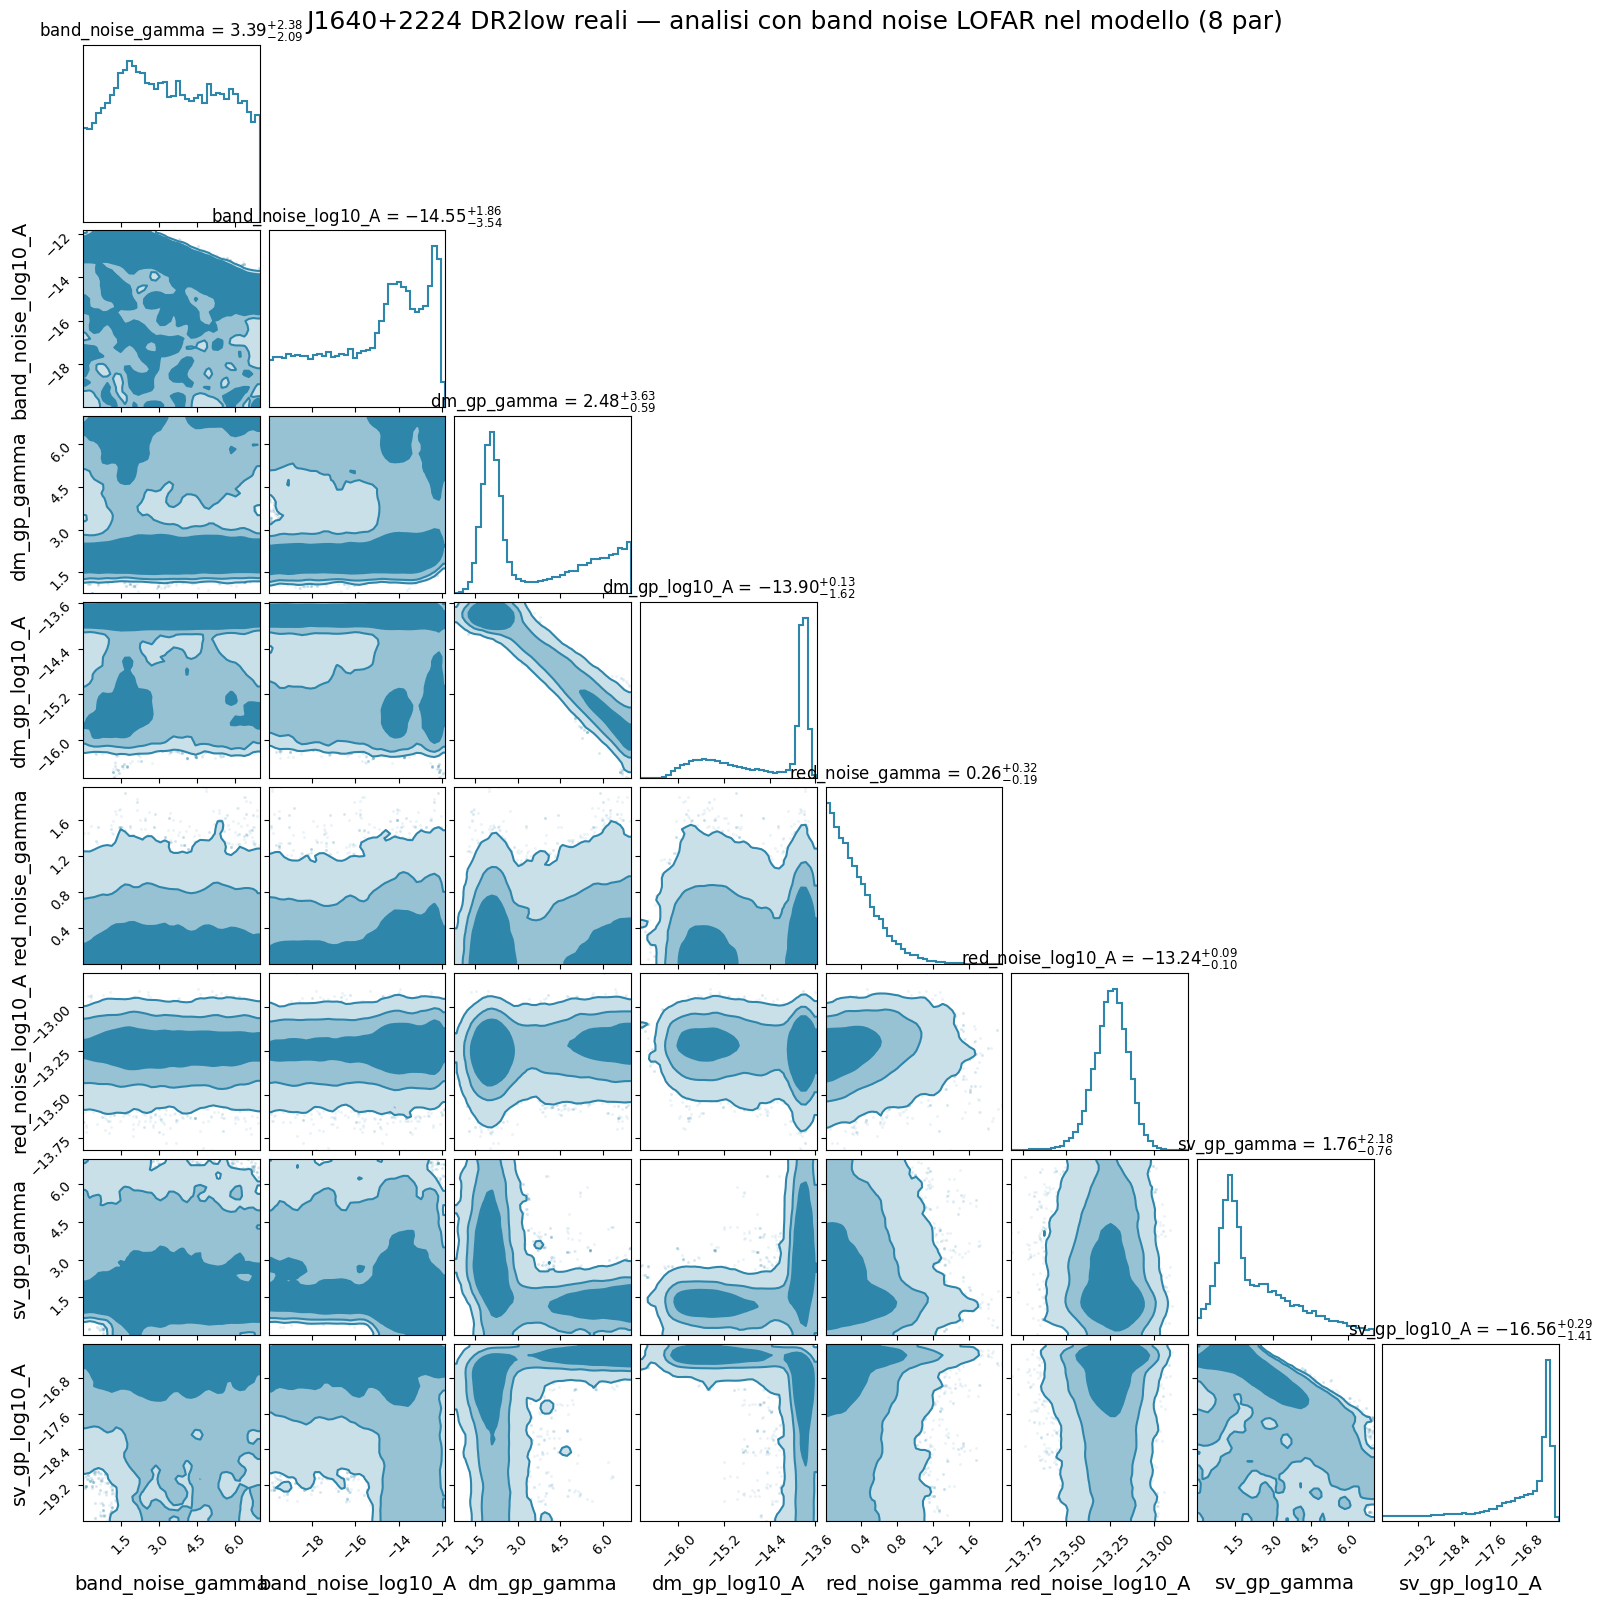

In [15]:
# Etichette pulite (senza il prefisso del pulsar)
clean_labels_real_bn = [name.replace('J1640+2224_', '') for name in logL_real_bn.params]

fig = corner.corner(
    chain_real_bn,
    labels=clean_labels_real_bn,
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#2E86AB',
    hist_kwargs={'color': '#2E86AB', 'linewidth': 1.5, "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 DR2low reali — analisi con band noise LOFAR nel modello (8 par)',
             fontsize=18, y=1.00)

fig.savefig('corner_real_bnmodel.png', dpi=150, bbox_inches='tight')

### Confronto: modello a 6 par vs modello a 8 par, dati reali

La catena a 6 parametri e quella del notebook 10 (`test_real_sv44/`, alpha = 4.4).
Il confronto e sui 6 parametri comuni.

In [16]:
chain_real_6par = np.loadtxt('./test_real_sv44/chain_1.txt')
chain_real_6par = chain_real_6par[len(chain_real_6par)//4:, :-4]

# ordine dei parametri della catena a 6 par = quello del modello standard
params_6par = ds.PulsarLikelihood(costruisci_modello(psr, band_noise=False)).logL.params

# dalla catena a 8 par prendo solo le 6 colonne comuni, nello stesso ordine
chain_real_comuni = chain_real_bn[:, [idx_real_bn[name] for name in params_6par]]

clean_labels_6par = [name.replace('J1640+2224_', '') for name in params_6par]

# mediane affiancate
for i, name in enumerate(params_6par):
    a16, a50, a84 = np.percentile(chain_real_6par[:, i], [16, 50, 84])
    b16, b50, b84 = np.percentile(chain_real_comuni[:, i], [16, 50, 84])
    s = np.sqrt(((a84 - a16)/2)**2 + ((b84 - b16)/2)**2)
    print(f"{name.replace('J1640+2224_', ''):20s}  6 par {a50:8.3f}   8 par {b50:8.3f}   diff {(b50 - a50)/s:6.2f} sigma")

dm_gp_gamma           6 par    2.286   8 par    2.480   diff   0.06 sigma
dm_gp_log10_A         6 par  -13.880   8 par  -13.898   diff  -0.01 sigma
red_noise_gamma       6 par    0.249   8 par    0.263   diff   0.04 sigma
red_noise_log10_A     6 par  -13.244   8 par  -13.241   diff   0.02 sigma
sv_gp_gamma           6 par    2.122   8 par    1.755   diff  -0.17 sigma
sv_gp_log10_A         6 par  -16.556   8 par  -16.560   diff  -0.00 sigma


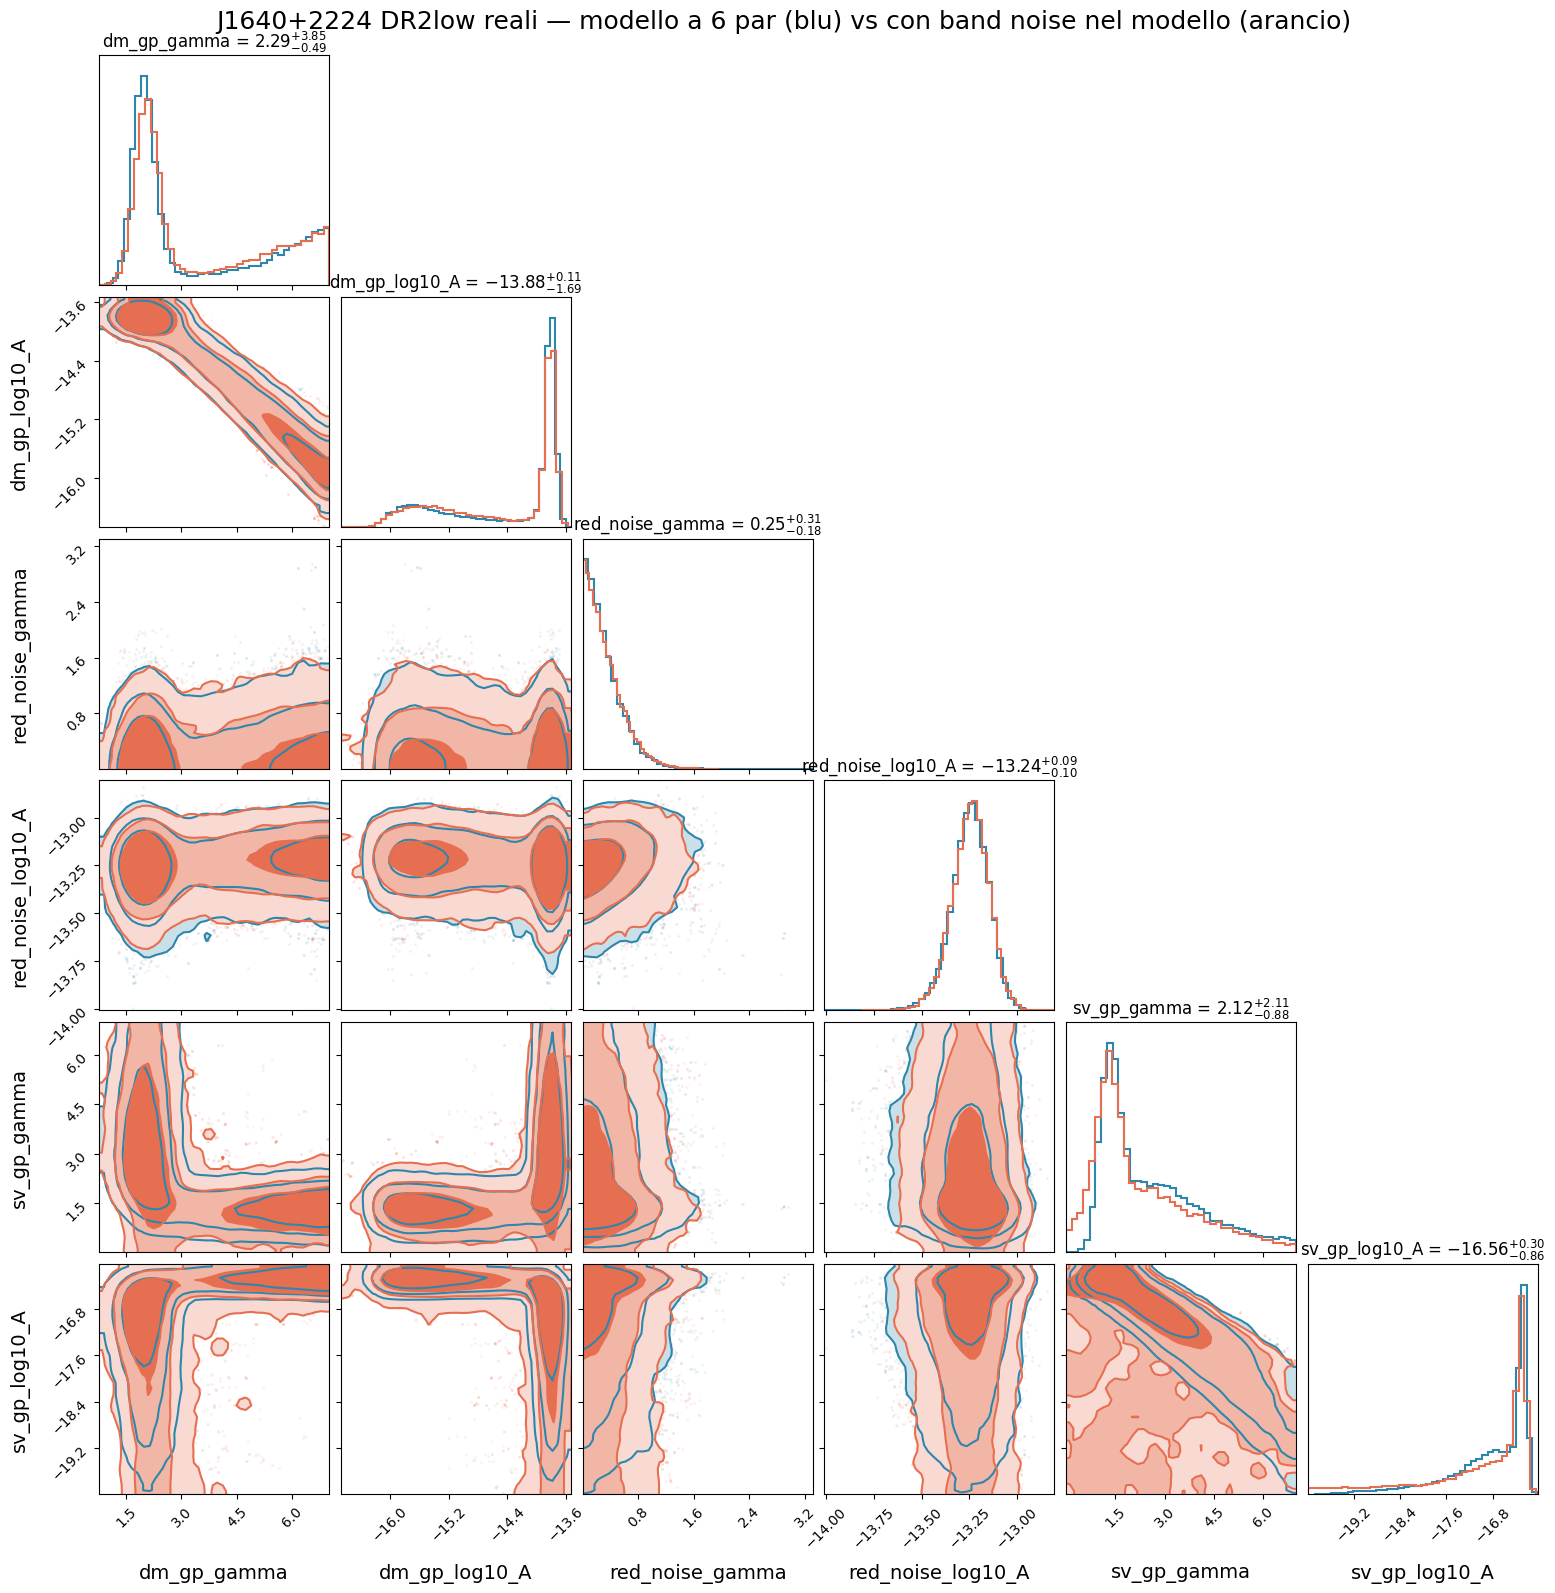

In [17]:
# Primo corner: modello a 6 par (senza band noise) in blu
fig = corner.corner(
    chain_real_6par,
    labels=clean_labels_6par,
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#2E86AB',
    hist_kwargs={'color': '#2E86AB', 'linewidth': 1.5, "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner: modello a 8 par (con band noise) in arancio scuro, sovrapposto
corner.corner(
    chain_real_comuni,
    labels=clean_labels_6par,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#E76F51',
    hist_kwargs={'color': '#E76F51', 'linewidth': 1.5, "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 DR2low reali — modello a 6 par (blu) vs con band noise nel modello (arancio)',
             fontsize=18, y=1.00)

fig.savefig('corner_real_6par_vs_8par.png', dpi=150, bbox_inches='tight')